# 01 · Data review

This notebook reviews the data downloaded from cBioPortal before any model is trained. It does not train anything. It only counts, checks and saves the TP53 labels.

It answers the following questions:
1. How many samples does each cohort have with expression and with DNA sequencing?
2. How many are left if we keep only primary tumors and one sample per patient?
3. Which TP53 variants are there, and what is the label with the rule we decided?
4. How many genes do the four cohorts share?
5. Are CPTAC 2020 and CPTAC GDC the same patients?
6. How are the PAM50 subtypes distributed, and what is the % of TP53 mutated tumors in each subtype?

**Cohorts:** TCGA-BRCA and METABRIC are the source. CPTAC and SMC 2018 are the target cohorts.

**Input:** `data/raw/` (created by `scripts/download_data.py`) and `resources/gene_id_mapping.csv` (catalog of protein-coding genes).
**Output:** `data/processed/revision/` (labels and summary tables).

*Note: this notebook was run before the repository was translated. The code comments, printed text and figure labels in the saved outputs are in Spanish. The results are the same.*

In [1]:
from pathlib import Path
import json
import re
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed" / "revision"
OUT.mkdir(parents=True, exist_ok=True)
GENE_CATALOG = ROOT / "resources" / "gene_id_mapping.csv"   # catálogo de genes codificantes del manuscrito

COHORTS = {
    "TCGA-BRCA": "brca_tcga_gdc",
    "METABRIC": "brca_metabric",
    "CPTAC": "breast_cptac_gdc",
    "SMC 2018": "brca_smc_2018",
}
ROLE = {"TCGA-BRCA": "fuente", "METABRIC": "fuente", "CPTAC": "objetivo", "SMC 2018": "objetivo"}
COLORS = {"TCGA-BRCA": "#1D9E75", "METABRIC": "#5DCAA5", "CPTAC": "#534AB7", "SMC 2018": "#AFA9EC"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Carpeta de datos:", RAW)

Carpeta de datos: D:\Purdue Intern\1st data\deep_learning\datos\raw


In [2]:
def read_case_list(study, name):
    """IDs de una lista de casos de cBioPortal (por ejemplo, las muestras secuenciadas)."""
    text = (RAW / study / "case_lists" / name).read_text(encoding="utf-8")
    line = next(l for l in text.splitlines() if l.startswith("case_list_ids"))
    return set(line.split(":", 1)[1].split())


def read_table(path, **kw):
    return pd.read_csv(path, sep="\t", comment="#", low_memory=False, **kw)


def expression_file(study):
    return next((RAW / study).glob("data_mrna*.txt"))


def expression_samples(study):
    header = pd.read_csv(expression_file(study), sep="\t", nrows=0).columns
    return [c for c in header if c not in ("Hugo_Symbol", "Entrez_Gene_Id")]

## Step 1 · Samples with expression and with sequencing

To train a model, both things are needed in the same sample:
- **Expression** (the X): the RNA-seq or microarray matrix.
- **DNA sequencing** (the Y): the list `cases_sequenced`. If a sample was sequenced and has no TP53 mutation, it is wild type (WT). If it was not sequenced, its status is unknown.

In [3]:
samples = {}
rows = []
for name, study in COHORTS.items():
    expr = set(expression_samples(study))
    seq = read_case_list(study, "cases_sequenced.txt")
    samples[name] = {"expr": expr, "seq": seq}
    rows.append({"Cohorte": name, "Rol": ROLE[name], "Con expresión": len(expr),
                 "Secuenciadas": len(seq), "Con las dos": len(expr & seq)})
step1 = pd.DataFrame(rows).set_index("Cohorte")
step1

,Rol,Con expresión,Secuenciadas,Con las dos
Cohorte,,,,
TCGA-BRCA,fuente,1097,971,967
METABRIC,fuente,1980,2433,1904
CPTAC,objetivo,133,126,105
SMC 2018,objetivo,168,186,167


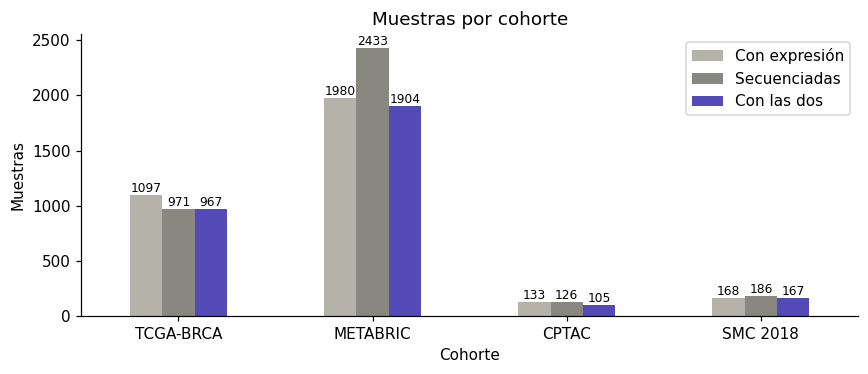

In [4]:
ax = step1[["Con expresión", "Secuenciadas", "Con las dos"]].plot.bar(
    figsize=(8, 3.5), color=["#B4B2A9", "#888780", "#534AB7"], rot=0)
ax.set_ylabel("Muestras")
ax.set_title("Muestras por cohorte")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.tight_layout()

## Step 2 · Only primary tumors and one sample per patient

Only **primary tumors** and **one sample per patient** are used (decision of 02-Oct-2026). There are two reasons:
1. Normal tissue or a metastasis has a different expression. It is not what we want to predict.
2. If a patient has two samples, one could end up in training and the other one in the test. The model would "recognize" the patient and the AUC would be inflated.

Each cohort stores the sample type in a different column. The table below shows which values there are.

In [5]:
clin = {}
for name, study in COHORTS.items():
    s = read_table(RAW / study / "data_clinical_sample.txt")
    clin[name] = s.set_index("SAMPLE_ID")

type_column = {"TCGA-BRCA": "SAMPLE_TYPE", "METABRIC": "SAMPLE_TYPE",
               "CPTAC": "SPECIMEN_TYPE", "SMC 2018": "SAMPLE_TYPE"}
for name, col in type_column.items():
    both = samples[name]["expr"] & samples[name]["seq"]
    print(f"{name} ({col}):", clin[name].loc[sorted(both), col].value_counts(dropna=False).to_dict())

TCGA-BRCA (SAMPLE_TYPE): {'Primary Tumor': 961, 'Metastatic': 6}
METABRIC (SAMPLE_TYPE): {'Primary': 1904}
CPTAC (SPECIMEN_TYPE): {'sample': 105}
SMC 2018 (SAMPLE_TYPE): {'Primary': 167}


In TCGA, CPTAC and SMC we have to check whether normal tissue or metastases appear. In METABRIC every sample is primary.

**Rule for one sample per patient:** if a patient has more than one primary sample, the first one in alphabetical order of its ID is kept. In TCGA this keeps the aliquot `01A` before `01B`. It is a simple fixed rule, decided before looking at the label.

In [6]:
PRIMARY_VALUES = {"Primary Tumor", "Primary", "sample"}   # 'sample' es el único valor de CPTAC GDC (se revisa arriba)

kept = {}
rows = []
for name in COHORTS:
    both = sorted(samples[name]["expr"] & samples[name]["seq"])
    c = clin[name].loc[both]
    primary = c[c[type_column[name]].isin(PRIMARY_VALUES)]
    one_per_patient = primary.reset_index().sort_values("SAMPLE_ID").drop_duplicates("PATIENT_ID")
    kept[name] = one_per_patient.set_index("SAMPLE_ID")
    rows.append({"Cohorte": name, "Con las dos": len(both), "Primarias": len(primary),
                 "Pacientes con más de una": int(primary["PATIENT_ID"].duplicated().sum()),
                 "Una por paciente": len(one_per_patient)})
step2 = pd.DataFrame(rows).set_index("Cohorte")
step2

,Con las dos,Primarias,Pacientes con más de una,Una por paciente
Cohorte,,,,
TCGA-BRCA,967,961,0,961
METABRIC,1904,1904,0,1904
CPTAC,105,105,0,105
SMC 2018,167,167,0,167


## Step 3 · The TP53 label

The rule was decided on 02-Oct-2026:

| Case | Label |
|---|---|
| At least one variant that **changes the protein** (missense, nonsense, frameshift, in-frame, splice site) | **Mutated (1)** |
| Silent variant at the **edge of an exon** that changes splicing: p.T125T (c.375G>T/A/C), p.E224E (c.672G>A) or p.Q331Q (c.993G>A) | **Mutated (1)** |
| Sequenced and **without any** TP53 variant | **WT (0)** |
| Only variants that **do not change the protein** (silent, intronic, UTR, splice region) | **Excluded** |

First, we look at which kinds of TP53 variants each cohort has.

In [7]:
mut = {}
for name, study in COHORTS.items():
    m = read_table(RAW / study / "data_mutations.txt",
                   usecols=lambda c: c in ("Hugo_Symbol", "Tumor_Sample_Barcode", "Variant_Classification",
                                           "HGVSp_Short", "HGVSc", "Mutation_Status", "Chromosome",
                                           "Start_Position", "Reference_Allele", "Tumor_Seq_Allele2"))
    mut[name] = m

tp53 = pd.concat([m[m.Hugo_Symbol == "TP53"].assign(Cohorte=n) for n, m in mut.items()])
variant_table = pd.crosstab(tp53.Variant_Classification, tp53.Cohorte)[list(COHORTS)]
variant_table

Cohorte,TCGA-BRCA,METABRIC,CPTAC,SMC 2018
Variant_Classification,,,,
Frame_Shift_Del,49,121,11,9
Frame_Shift_Ins,15,40,0,4
In_Frame_Del,6,29,1,2
In_Frame_Ins,0,7,0,0
Missense_Mutation,201,510,23,54
Nonsense_Mutation,48,126,13,16
Silent,0,9,1,0
Splice_Region,1,3,1,0
Splice_Site,24,52,1,4


In [8]:
print("Mutation_Status de las variantes de TP53 (¿hay germinales?):")
print(tp53.groupby("Cohorte").Mutation_Status.value_counts(dropna=False).to_string())

Mutation_Status de las variantes de TP53 (¿hay germinales?):
Cohorte    Mutation_Status
CPTAC      Somatic             51
METABRIC   NaN                897
SMC 2018   NaN                 89
TCGA-BRCA  Somatic            344


In [9]:
PROTEIN_CHANGING = {"Missense_Mutation", "Nonsense_Mutation", "Frame_Shift_Del", "Frame_Shift_Ins",
                    "In_Frame_Del", "In_Frame_Ins", "Splice_Site", "Translation_Start_Site", "Nonstop_Mutation"}
# Se buscan por el cambio en el ADN (HGVSc). El cambio de proteína se escribe distinto
# en cada estudio: p.T125= en METABRIC y p.X125_splice en GDC.
EXON_BORDER_SILENT = r"c\.(?:375G>[TAC]|672G>A|993G>A)$"
is_border = tp53.HGVSc.fillna("").str.contains(EXON_BORDER_SILENT, regex=True)

tp53["Cuenta como mutada"] = tp53.Variant_Classification.isin(PROTEIN_CHANGING) | is_border

border = tp53[is_border]
print("Silenciosas de borde de exón encontradas:", len(border))
border[["Cohorte", "Tumor_Sample_Barcode", "Variant_Classification", "HGVSp_Short", "HGVSc"]]

Silenciosas de borde de exón encontradas: 5


,Cohorte,Tumor_Sample_Barcode,Variant_Classification,HGVSp_Short,HGVSc
73565,TCGA-BRCA,TCGA-BH-A0BW-01A,Splice_Region,p.X125_splice,ENST00000269305.9:c.375G>C
1022,METABRIC,MTS-T0313,Splice_Region,p.T125=,ENST00000269305.4:c.375G>C
5027,METABRIC,MTS-T1191,Splice_Region,p.T125=,ENST00000269305.4:c.375G>T
16369,METABRIC,MB-6272,Splice_Region,p.T125=,ENST00000269305.4:c.375G>A
8740,CPTAC,97cc4d46-cf80-41f1-b99c-bc4829,Splice_Region,p.X125_splice,ENST00000269305.9:c.375G>T


In [10]:
labels = []
for name in COHORTS:
    k = kept[name]
    t = tp53[tp53.Cohorte == name]
    per_sample = t.groupby("Tumor_Sample_Barcode")["Cuenta como mutada"].any()
    status = pd.Series("WT", index=k.index)
    status[status.index.isin(per_sample[per_sample].index)] = "Mutado"
    status[status.index.isin(per_sample[~per_sample].index)] = "Excluido"
    labels.append(pd.DataFrame({"cohort": name, "sample_id": k.index, "patient_id": k["PATIENT_ID"].values,
                                "tp53_status": status.values}))
labels = pd.concat(labels, ignore_index=True)

step3 = labels.groupby("cohort").tp53_status.value_counts().unstack(fill_value=0).loc[list(COHORTS)]
step3 = step3[["Mutado", "WT", "Excluido"]]
step3["n final"] = step3["Mutado"] + step3["WT"]
step3["% mutado"] = (100 * step3["Mutado"] / step3["n final"]).round(1)
step3

tp53_status,Mutado,WT,Excluido,n final,% mutado
cohort,,,,,
TCGA-BRCA,331,630,0,961,34.4
METABRIC,659,1240,5,1899,34.7
CPTAC,41,64,0,105,39.0
SMC 2018,81,86,0,167,48.5


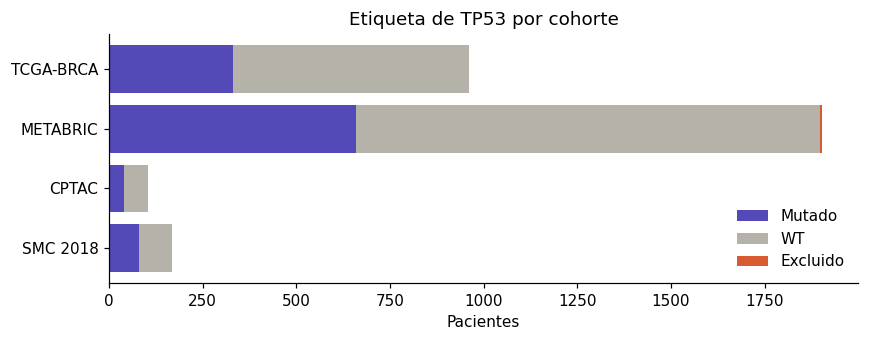

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(step3))
for col, color in [("Mutado", "#534AB7"), ("WT", "#B4B2A9"), ("Excluido", "#D85A30")]:
    ax.barh(step3.index, step3[col], left=left, color=color, label=col)
    left += step3[col].values
ax.invert_yaxis()
ax.set_xlabel("Pacientes")
ax.set_title("Etiqueta de TP53 por cohorte")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

**Comparison with the previous machine learning manuscript:** there, CPTAC had 105 patients and SMC had 167. The rule at that time counted **any** TP53 variant as mutated. The new rule excludes the variants that do not change the protein. In CPTAC and SMC no tumor had only variants of that kind, so the n are the same as in the manuscript. The only silent variant in CPTAC (p.V272=) is in a tumor that also has another mutation.

**The silent variants at the edge of an exon** are searched by their DNA change (`c.375G>T`, etc.), because each study writes the protein change in a different way (`p.T125=` in METABRIC, `p.X125_splice` in GDC). Five appeared, all at codon 125. With the rule, they count as mutated.

### METABRIC: does the gene panel cover TP53?
METABRIC did not sequence the whole genome. It used a panel of 173 genes. If TP53 were not in the panel of some sample, "no mutation" would not mean WT. We ask the cBioPortal API.

In [12]:
API = "https://www.cbioportal.org/api"
HEADERS = {"Accept": "application/json", "User-Agent": "tp53-dl-review/1.0 (research)"}  # cBioPortal rechaza el User-Agent por defecto de Python


def api_get(path):
    with urllib.request.urlopen(urllib.request.Request(API + path, headers=HEADERS), timeout=120) as r:
        return json.load(r)


def api_post(path, body):
    req = urllib.request.Request(API + path, data=json.dumps(body).encode(), method="POST",
                                 headers={**HEADERS, "Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=300) as r:
        return json.load(r)


panel_cache = RAW / "api_clinica" / "brca_metabric__panel_por_muestra.json"
if not panel_cache.exists():
    panel_data = api_post("/molecular-profiles/brca_metabric_mutations/gene-panel-data/fetch",
                          {"sampleListId": "brca_metabric_sequenced"})
    panels = pd.Series([p["genePanelId"] for p in panel_data]).value_counts()
    panel_info = {pid: sorted(g["hugoGeneSymbol"] for g in api_get(f"/gene-panels/{pid}")["genes"]) for pid in panels.index}
    panel_cache.write_text(json.dumps({"muestras_por_panel": panels.to_dict(), "genes": panel_info}), encoding="utf-8")
cached = json.loads(panel_cache.read_text(encoding="utf-8"))
print("Panel por muestra secuenciada:", cached["muestras_por_panel"])
for pid, panel_genes in cached["genes"].items():
    print(f"{pid}: {len(panel_genes)} genes, ¿incluye TP53? {'TP53' in panel_genes}")

Panel por muestra secuenciada: {'METABRIC_173': 2433}
METABRIC_173: 173 genes, ¿incluye TP53? True


## Step 4 · Genes shared by the four cohorts

To move a model from one cohort to another, the input must have **the same genes in the same order**. The cohorts name the genes in different ways:
- TCGA and CPTAC (GDC) identify the genes only by their **Entrez ID** (a number).
- METABRIC has the Entrez ID and the symbol (for example, `ESR1`).
- SMC has the symbol, but **its Entrez column is empty**.

That is why the cohorts are joined by Entrez ID. Then we count how many are **protein-coding genes**, with the same catalog used in the manuscript (`resources/gene_id_mapping.csv`). TP53 is removed from X.

### Translating the SMC gene symbols
SMC is from 2018 and uses **old gene symbols**. For example, TIGAR (a p53 target) appears as `C12orf5`. If only current symbols are used, about 1,450 protein-coding genes are lost in **all** cohorts, because the model can only use genes present in the four.

To recover them we use the official gene table (HGNC), which stores the **previous symbols** of each gene. The rule has three steps, in this order:
1. If the symbol is a **current symbol** (in the catalog or in HGNC), that gene is used.
2. If not, and it is the **previous symbol of only one gene**, it is replaced by the new symbol.
3. If the previous symbol belongs to more than one gene, there is no way to know which one it is, and it is left untranslated.

In [13]:
hgnc = pd.read_csv(RAW / "referencias" / "hgnc_complete_set.txt", sep="\t", low_memory=False,
                   usecols=["symbol", "prev_symbol", "entrez_id"]).dropna(subset=["entrez_id"])
hgnc["entrez_id"] = hgnc.entrez_id.astype(int)

catalog = pd.read_csv(GENE_CATALOG)
protein_coding = set(catalog.loc[catalog.type == "protein-coding", "entrezGeneId"].astype(int))

current_name = dict(zip(catalog.hugoGeneSymbol, catalog.entrezGeneId))
current_name.update({s: e for s, e in zip(hgnc.symbol, hgnc.entrez_id) if s not in current_name})
previous = hgnc.assign(prev=hgnc.prev_symbol.str.split("|")).explode("prev").dropna(subset=["prev"])
previous = previous[~previous.prev.isin(current_name)]
n_genes_per_prev = previous.groupby("prev").entrez_id.nunique()
previous_name = previous[previous.prev.isin(n_genes_per_prev[n_genes_per_prev == 1].index)]
previous_name = dict(zip(previous_name.prev, previous_name.entrez_id))
new_symbol = hgnc.drop_duplicates("entrez_id").set_index("entrez_id").symbol


def translate_symbol(s):
    if s in current_name:
        return current_name[s], "nombre actual"
    if s in previous_name:
        return previous_name[s], "nombre anterior"
    return np.nan, "sin traducir"


smc_symbols = pd.read_csv(expression_file("brca_smc_2018"), sep="\t", usecols=["Hugo_Symbol"]).Hugo_Symbol
smc_translation = pd.DataFrame([translate_symbol(s) for s in smc_symbols], columns=["entrez", "como"], index=smc_symbols)
print(smc_translation.como.value_counts().to_string())
print("Nombres anteriores ambiguos (más de un gen, se ignoran):", int((n_genes_per_prev > 1).sum()))
examples = smc_translation[smc_translation.como == "nombre anterior"].head(8)
pd.DataFrame({"Nombre en SMC": examples.index, "Nombre nuevo": examples.entrez.map(new_symbol).values})

como
nombre actual      19635
sin traducir        9135
nombre anterior     1603
Nombres anteriores ambiguos (más de un gen, se ignoran): 84


,Nombre en SMC,Nombre nuevo
0,A2MP1,PZP2P
1,AAED1,PRXL2C
2,AARS,AARS1
3,AATK-AS1,PVALEF
4,ABP1,AOC1
5,ACN9,SDHAF3
6,ACPL2,PXYLP1
7,ACPP,ACP3


In [14]:
def entrez_ids(study):
    """Entrez ID de cada fila. SMC trae la columna vacía: se traduce su nombre de gen."""
    e = pd.read_csv(expression_file(study), sep="\t", usecols=lambda c: c in ("Hugo_Symbol", "Entrez_Gene_Id"))
    if e["Entrez_Gene_Id"].isna().all():
        return pd.Series([translate_symbol(s)[0] for s in e["Hugo_Symbol"]])
    return e["Entrez_Gene_Id"]


genes = {}
rows = []
for name, study in COHORTS.items():
    ids = entrez_ids(study)
    valid = ids.dropna().astype(int)
    genes[name] = set(valid)
    rows.append({"Cohorte": name, "Filas": len(ids), "Sin Entrez ID": int(ids.isna().sum()),
                 "Entrez repetidos": int(valid.duplicated().sum()), "Entrez únicos": len(genes[name]),
                 "Codificantes": len(genes[name] & protein_coding)})
step4 = pd.DataFrame(rows).set_index("Cohorte")
step4

,Filas,Sin Entrez ID,Entrez repetidos,Entrez únicos,Codificantes
Cohorte,,,,,
TCGA-BRCA,40796,0,35,40761,19189
METABRIC,20603,0,411,20192,18289
CPTAC,40796,0,35,40761,19189
SMC 2018,30373,9135,93,21145,18664


In [15]:
TP53_ENTREZ = 7157
common = set.intersection(*genes.values()) - {TP53_ENTREZ}
common_coding = common & protein_coding
source_only = (genes["TCGA-BRCA"] & genes["METABRIC"]) - {TP53_ENTREZ}

summary_genes = pd.Series({
    "Comunes a TCGA y METABRIC (fuente)": len(source_only),
    "Comunes a las 4 cohortes": len(common),
    "Comunes a las 4 y codificantes": len(common_coding),
}, name="Genes (sin TP53)")
summary_genes.to_frame()

,Genes (sin TP53)
Comunes a TCGA y METABRIC (fuente),19673
Comunes a las 4 cohortes,19054
Comunes a las 4 y codificantes,18040


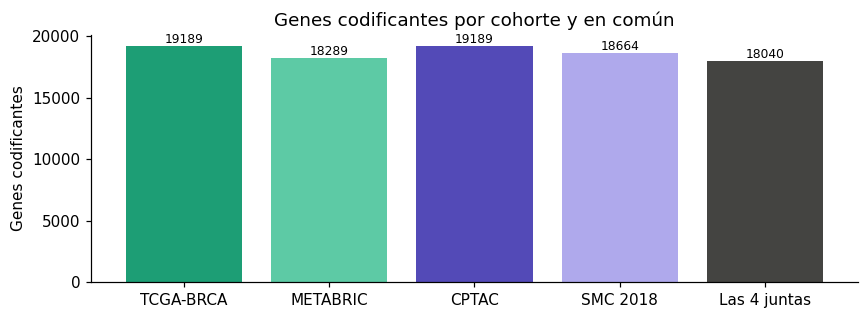

In [16]:
fig, ax = plt.subplots(figsize=(8, 3))
vals = [len(genes[n] & protein_coding) for n in COHORTS] + [len(common_coding)]
labels_g = list(COHORTS) + ["Las 4 juntas"]
ax.bar(labels_g, vals, color=[COLORS[n] for n in COHORTS] + ["#444441"])
ax.bar_label(ax.containers[0], fontsize=8)
ax.set_ylabel("Genes codificantes")
ax.set_title("Genes codificantes por cohorte y en común")
plt.tight_layout()

With the SMC symbols translated, the four cohorts share about 18,000 protein-coding genes. Now the main limit is METABRIC, because its microarray does not measure every gene. "Shared by the 4" also includes some non-coding genes that SMC names with their current symbol.

## Step 5 · Are CPTAC 2020 and CPTAC GDC the same patients?

cBioPortal has two breast cancer CPTAC studies:
- **CPTAC GDC** (`breast_cptac_gdc`): the one we use, with RNA-seq in TPM.
- **CPTAC 2020** (`brca_cptac_2020`, Krug et al. 2020): it has PAM50 and ER, which GDC lacks.

They do not share IDs (`CPT000814` vs `01BR001`). But if they are the same tumors, they must have **the same somatic mutations**. We compare the mutations (gene + protein change) of each GDC sample with each 2020 sample. The 2020 mutations are downloaded from the API once and saved.

In [17]:
cache = RAW / "api_clinica" / "brca_cptac_2020__mutaciones.tsv"
if not cache.exists():
    lists = {l["sampleListId"] for l in api_get("/studies/brca_cptac_2020/sample-lists")}
    sample_list = "brca_cptac_2020_sequenced" if "brca_cptac_2020_sequenced" in lists else "brca_cptac_2020_all"
    rows = api_post("/molecular-profiles/brca_cptac_2020_mutations/mutations/fetch?projection=DETAILED",
                    {"sampleListId": sample_list})
    pd.DataFrame([{"sampleId": r["sampleId"], "patientId": r["patientId"],
                   "gene": r["gene"]["hugoGeneSymbol"], "proteinChange": r.get("proteinChange"),
                   "mutationType": r.get("mutationType")} for r in rows]).to_csv(cache, sep="\t", index=False)
cptac2020 = pd.read_csv(cache, sep="\t")
print("Mutaciones de CPTAC 2020:", len(cptac2020), "en", cptac2020.sampleId.nunique(), "muestras")

Mutaciones de CPTAC 2020: 19655 en 122 muestras


In [18]:
def fingerprint(df, sample_col, gene_col, prot_col):
    d = df.dropna(subset=[prot_col])
    keys = d[gene_col] + ":" + d[prot_col].str.replace("p.", "", regex=False)
    return keys.groupby(d[sample_col]).apply(set)

fp_gdc = fingerprint(mut["CPTAC"], "Tumor_Sample_Barcode", "Hugo_Symbol", "HGVSp_Short")
fp_2020 = fingerprint(cptac2020, "sampleId", "gene", "proteinChange")

matches = []
for s, a in fp_gdc.items():
    shared = fp_2020.apply(lambda b: len(a & b))
    best = shared.idxmax()
    second = shared.drop(best).max()
    matches.append({"gdc_sample": s, "cptac2020_sample": best, "compartidas": int(shared[best]),
                    "segunda_mejor": int(second), "mutaciones_gdc": len(a)})
matches = pd.DataFrame(matches)
matches["coincide"] = (matches.compartidas >= 3) & (matches.compartidas >= 3 * matches.segunda_mejor.clip(lower=1))
print("Muestras de GDC con una pareja clara en 2020:", int(matches.coincide.sum()), "de", len(matches))
matches.describe()[["compartidas", "segunda_mejor"]]

Muestras de GDC con una pareja clara en 2020: 112 de 126


,compartidas,segunda_mejor
count,126.000000,126.000000
mean,54.444444,0.420635
std,86.997246,0.495632
min,0.000000,0.000000
25%,18.000000,0.000000
50%,30.000000,0.000000
75%,56.000000,1.000000
max,617.000000,1.000000


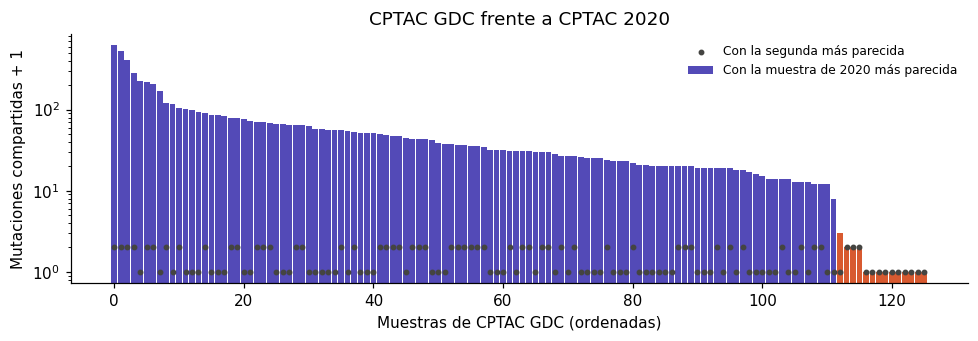

In [19]:
m = matches.sort_values("compartidas", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(m.index, m.compartidas + 1, color=np.where(m.coincide, "#534AB7", "#D85A30"), width=0.9,
       label="Con la muestra de 2020 más parecida")
ax.scatter(m.index, m.segunda_mejor + 1, color="#444441", s=8, zorder=3,
           label="Con la segunda más parecida")
ax.set_yscale("log")
ax.set_xlabel("Muestras de CPTAC GDC (ordenadas)")
ax.set_ylabel("Mutaciones compartidas + 1")
ax.set_title("CPTAC GDC frente a CPTAC 2020")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

Each bar is a CPTAC GDC tumor. Its height is how many mutations it shares with the most similar 2020 tumor. The gray point is how many it shares with the second most similar one. When the bar is high and the point is low, the tumor matches **only one** 2020 tumor, so it is the same tumor (purple). The orange bars have no clear match. They are probably patients that are not in the 2020 study. The vertical axis is logarithmic, and 1 is added so that zeros can be shown.

The rule for a "clear match" (at least 3 shared mutations, and at least 3 times more than with the second one) is only used in this review.

## Step 6 · Subtypes and % of TP53 mutated tumors per subtype

The subtype is not part of X (decision of 02-Oct-2026), but it is useful to check the **ER confounder**. TP53 is mutated much more often in basal tumors than in luminal A tumors. If the cohorts have a different mix of subtypes, that also changes the % of mutated tumors.

Sources of the PAM50 subtype:
- **TCGA:** PanCancer Atlas (per patient), downloaded from the API.
- **METABRIC:** column `CLAUDIN_SUBTYPE` of its clinical data.
- **SMC:** column `PAM50_SUBTYPE` of its clinical data.
- **CPTAC:** PAM50 of CPTAC 2020, joined with the matches of step 5.

In [20]:
def harmonize(v):
    if pd.isna(v):
        return np.nan
    v = str(v).replace("BRCA_", "").lower()
    for key, out in [("luma", "LumA"), ("luminala", "LumA"), ("lumb", "LumB"), ("luminalb", "LumB"),
                     ("her2", "Her2"), ("basal", "Basal"), ("claudin", "Claudin-low"), ("normal", "Normal")]:
        if v.replace(" ", "").startswith(key):
            return out
    return "Otro"

pam50 = {}
t = pd.read_csv(RAW / "api_clinica" / "brca_tcga_pan_can_atlas_2018__SUBTYPE.tsv", sep="\t")
pam50["TCGA-BRCA"] = kept["TCGA-BRCA"]["PATIENT_ID"].map(t.set_index("patientId")["value"])
mb = read_table(RAW / "brca_metabric" / "data_clinical_patient.txt").set_index("PATIENT_ID")
pam50["METABRIC"] = kept["METABRIC"]["PATIENT_ID"].map(mb["CLAUDIN_SUBTYPE"])
pam50["SMC 2018"] = clin["SMC 2018"].loc[kept["SMC 2018"].index, "PAM50_SUBTYPE"]
c20 = pd.read_csv(RAW / "api_clinica" / "brca_cptac_2020__PAM50.tsv", sep="\t").set_index("sampleId")["value"]
pair = matches[matches.coincide].set_index("gdc_sample")["cptac2020_sample"]
pam50["CPTAC"] = pd.Series(kept["CPTAC"].index, index=kept["CPTAC"].index).map(pair).map(c20)

labels["pam50"] = [harmonize(pam50[r.cohort].get(r.sample_id, np.nan)) for r in labels.itertuples()]
labeled = labels[labels.tp53_status != "Excluido"].copy()
labeled["mutado"] = (labeled.tp53_status == "Mutado").astype(int)

order = ["LumA", "LumB", "Her2", "Basal", "Normal", "Claudin-low", "Otro"]
counts = pd.crosstab(labeled.pam50.fillna("Sin dato"), labeled.cohort)[list(COHORTS)]
counts = counts.reindex([o for o in order + ["Sin dato"] if o in counts.index])
counts

cohort,TCGA-BRCA,METABRIC,CPTAC,SMC 2018
pam50,,,,
LumA,464,676,43,46
LumB,186,459,15,65
Her2,74,220,10,18
Basal,160,199,19,36
Normal,33,140,4,2
Claudin-low,0,199,0,0
Otro,0,6,0,0
Sin dato,44,0,14,0


cohort,TCGA-BRCA,METABRIC,CPTAC,SMC 2018
pam50,,,,
LumA,11.0,12.0,19.0,13.0
LumB,37.0,24.0,27.0,46.0
Her2,70.0,70.0,50.0,83.0
Basal,89.0,88.0,84.0,81.0
Normal,30.0,23.0,75.0,50.0
Claudin-low,NaN,52.0,NaN,NaN


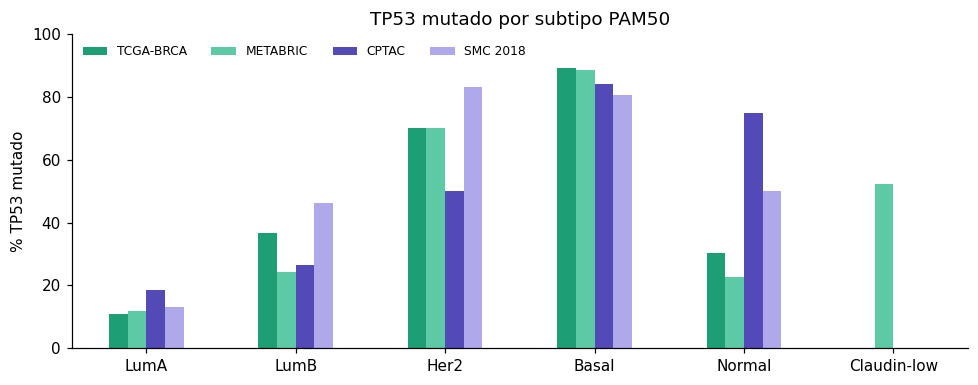

In [21]:
pct = (labeled.dropna(subset=["pam50"]).groupby(["pam50", "cohort"]).mutado.mean().unstack() * 100)
pct = pct.reindex([o for o in order if o in pct.index and o != "Otro"])[list(COHORTS)]
ax = pct.plot.bar(figsize=(9, 3.6), color=[COLORS[n] for n in COHORTS], rot=0)
ax.set_ylabel("% TP53 mutado")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.set_title("TP53 mutado por subtipo PAM50")
ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper left")
plt.tight_layout()
pct.round(0)

In the four cohorts, TP53 is mutated in more than 80% of basal tumors and in less than 20% of luminal A tumors. That is why the subtype alone already predicts a good part of the TP53 status. This is the **ER confounder**, and it has to be checked whether the model learns something beyond the subtype.

Be careful with the percentages of subtypes with few cases. For example, Normal has 4 tumors in CPTAC and 2 in SMC.

## Summary and saved files

The final table brings together what is left for the study. The last column shows how many patients are left to be drawn as "local patients" after 40 are set aside for the exam (only for the target cohorts).

In [22]:
final = step3[["n final", "Mutado", "WT", "% mutado"]].copy()
final.insert(0, "Rol", [ROLE[n] for n in final.index])
final["Fuera del examen (n − 40)"] = [n - 40 if ROLE[c] == "objetivo" else "—" for c, n in final["n final"].items()]
final["Genes comunes codificantes (sin TP53)"] = len(common_coding)
display(final)

labels.to_csv(OUT / "etiquetas_tp53.csv", index=False)
matches.to_csv(OUT / "cptac_gdc_vs_2020.csv", index=False)
pd.Series(sorted(common_coding), name="entrez_gene_id").to_csv(OUT / "genes_comunes_codificantes.csv", index=False)
smc_translation.rename_axis("hugo_symbol_smc").to_csv(OUT / "smc_traduccion_nombres.csv")
summary = {
    "muestras": step1.to_dict(), "primarias_una_por_paciente": step2.to_dict(),
    "etiqueta_tp53": step3.to_dict(), "genes": summary_genes.to_dict(),
    "cptac_parejas_claras": int(matches.coincide.sum()), "cptac_gdc_muestras": int(len(matches)),
}
(OUT / "resumen_revision.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardado en", OUT)

tp53_status,Rol,n final,Mutado,WT,% mutado,Fuera del examen (n − 40),Genes comunes codificantes (sin TP53)
cohort,,,,,,,
TCGA-BRCA,fuente,961,331,630,34.4,—,18040
METABRIC,fuente,1899,659,1240,34.7,—,18040
CPTAC,objetivo,105,41,64,39.0,65,18040
SMC 2018,objetivo,167,81,86,48.5,127,18040


Guardado en D:\Purdue Intern\1st data\deep_learning\datos\processed\revision


## What was decided after this review

1. Repeated Entrez IDs: the row with the highest mean expression is kept. It is applied in notebook 02.
2. CPTAC uses the PAM50 of CPTAC 2020.
3. The old SMC symbols are translated with HGNC.
4. The exam has 40 patients, with the final n of CPTAC (105) and SMC (167). It is built in notebook 04.

It is important to mention that METABRIC does not say whether its variants are somatic or germline (`Mutation_Status` is empty).